# Compression 04 — Codage entropique ANS en C#

**Navigation** : [Index](README.md) | [Python](Compression-04-ANS-Python.ipynb) | [LZ77](Compression-03-LZ77-Python.ipynb)

**Objectifs** : construire rANS transparent puis par blocs ; examiner les tables tANS ; comparer coûts et réversibilité.

**Prérequis** : C#, entropie, Huffman et entiers. **Durée** : 90 minutes.


In [1]:
using System;
using System.Linq;
using System.Collections.Generic;
using System.Numerics;
using System.IO;
using System.IO.Compression;
using System.Security.Cryptography;
using System.Diagnostics;
using System.Text;

public class Rans {
 public int[] Symbols, F, Cdf, Slot; public int M;
 public Rans(Dictionary<int,int> freq) {
  if(freq.Count==0 || freq.Values.Any(v=>v<=0)) throw new ArgumentException("Modèle vide ou fréquence non positive");
  Symbols=freq.Keys.OrderBy(x=>x).ToArray(); F=Symbols.Select(x=>freq[x]).ToArray(); Cdf=new int[F.Length];
  for(int i=0;i<F.Length;i++){Cdf[i]=M; M=checked(M+F[i]);}
  Slot=new int[M]; for(int i=0;i<F.Length;i++) for(int j=Cdf[i];j<Cdf[i]+F[i];j++) Slot[j]=i;
 }
 public BigInteger Encode(BigInteger x,int s){int i=Array.IndexOf(Symbols,s); if(i<0) throw new ArgumentException("Symbole absent"); return x/F[i]*M+Cdf[i]+x%F[i];}
 public (BigInteger,int) Decode(BigInteger x){int slot=(int)(x%M),i=Slot[slot]; return (x/M*F[i]+slot-Cdf[i],Symbols[i]);}
 public static byte[] BlocksEncode(int[] message, Dictionary<int,int> f,int B){
  if(B<=0) throw new ArgumentException("Taille de bloc"); var m=new Rans(f); int count=(int)(((long)message.Length+B-1)/B); if(count>65535)throw new ArgumentException("Nombre de blocs");
  var lengths=new List<int>(); var body=new List<byte>();
  for(int start=0;start<message.Length;start+=B){BigInteger x=m.M; foreach(int s in message.Skip(start).Take(B)) x=m.Encode(x,s); int len=(int)x.GetBitLength(); if(len>65535)throw new ArgumentException("État trop long"); lengths.Add(len);body.AddRange(x.ToByteArray(true,false));}
  var output=new List<byte>{1,(byte)(count>>8),(byte)count}; for(int shift=56;shift>=0;shift-=8)output.Add((byte)((ulong)message.Length>>shift)); foreach(int len in lengths){output.Add((byte)(len>>8));output.Add((byte)len);} output.AddRange(body);return output.ToArray();
 }
 public static int[] BlocksDecode(byte[] data,Dictionary<int,int> f,int B,int total){
  if(B<=0||total<0||data.Length<11||data[0]!=1)throw new ArgumentException("Cadre invalide"); var m=new Rans(f);int count=data[1]*256+data[2];ulong recorded=0;for(int i=3;i<11;i++)recorded=(recorded<<8)|data[i];if(recorded!=(ulong)total||count!=((long)total+B-1)/B||data.Length<11+2*count)throw new ArgumentException("Nombre de blocs ou en-tête");
  int pos=11+2*count,remaining=total;var result=new List<int>();for(int i=0;i<count;i++){int len=data[11+2*i]*256+data[12+2*i],bytes=(len+7)/8;if(len==0||pos+bytes>data.Length)throw new ArgumentException("État tronqué");var x=new BigInteger(data.AsSpan(pos,bytes),true,false);pos+=bytes;if(x.GetBitLength()!=len)throw new ArgumentException("Longueur incorrecte");int n=Math.Min(B,remaining);remaining-=n;var block=new List<int>();for(int j=0;j<n;j++){var d=m.Decode(x);x=d.Item1;block.Add(d.Item2);}if(x!=m.M)throw new ArgumentException("État final incorrect");block.Reverse();result.AddRange(block);}if(remaining!=0||pos!=data.Length)throw new ArgumentException("Octets surnuméraires");return result.ToArray();
 }
}
public class Bits {
 public List<byte> Data=new(); public int Count;
 public void Push(int value,int n){for(int j=0;j<n;j++){if(Count%8==0)Data.Add(0);if(((value>>j)&1)!=0)Data[Count/8]|=(byte)(1<<(Count%8));Count++;}}
 public int Pop(int n){if(n>Count)throw new ArgumentException("Flot tronqué");int v=0;for(int j=0;j<n;j++){Count--;v=(v<<1)|((Data[Count/8]>>(Count%8))&1);if(Count%8==0)Data.RemoveAt(Data.Count-1);}return v;}
}
public class Tans {
 public int N,L; public Dictionary<int,List<(int b,int k,int u)>> Enc=new(); public (int s,int k,int b)[] Dec;
 public static int BitLen(int v)=>32-BitOperations.LeadingZeroCount((uint)v);
 public static Dictionary<int,int> Scale(Dictionary<int,int> raw,int L){int N=1<<L;if(raw.Count<2||raw.Count>N||raw.Values.Any(x=>x<=0))throw new ArgumentException("Modèle tANS invalide");double total=raw.Values.Sum();var e=raw.ToDictionary(k=>k.Key,k=>Math.Max(1,(int)Math.Round(k.Value*N/total)));int rest=N-e.Values.Sum();var order=e.Keys.OrderByDescending(s=>e[s]).ThenBy(s=>s).ToArray();int first=order[0];if(e[first]+rest>=1&&e[first]+rest<N){e[first]+=rest;rest=0;}while(rest!=0){bool progress=false;foreach(int s in order){if(rest==0)break;if(rest>0){e[s]++;rest--;progress=true;}else if(e[s]>1){e[s]--;rest++;progress=true;}}if(!progress)throw new ArgumentException("Échelle impossible");}return e;}
 public Tans(Dictionary<int,int> freq,int l,bool rotation=true){L=l;N=1<<L;if(freq.Values.Sum()!=N||freq.Values.Any(x=>x<1||x>=N))throw new ArgumentException("Échelle invalide");
  int[] symbols=freq.Keys.OrderBy(x=>x).ToArray(),spread=Enumerable.Repeat(-1,N).ToArray();int pos=0,step=N/5*2+1;foreach(int s in symbols)for(int i=0;i<freq[s];i++){while(spread[pos]!=-1)pos=(pos+1)%N;spread[pos]=s;pos=(pos+step)%N;}
  Dec=new (int,int,int)[N];foreach(int s in symbols){int f=freq[s];var ks=Enumerable.Range(f,f).Select(w=>L-BitLen(w)+1).OrderByDescending(k=>k).ToArray();var slots=Enumerable.Range(0,N).Where(u=>spread[u]==s).ToArray();int d=rotation?f/2:0,b=N;var list=new List<(int,int,int)>();for(int i=0;i<f;i++){int k=ks[i],u=slots[(i+d)%f];list.Add((b,k,u));Dec[u]=(s,k,b);b+=1<<k;}if(b!=2*N)throw new Exception("Pavage incorrect");Enc[s]=list;}
 }
 public Bits Encode(IEnumerable<int> message){var bits=new Bits();int x=N;foreach(int s in message){bool found=false;foreach(var (b,k,u) in Enc[s])if(x>=b&&x<b+(1<<k)){bits.Push(x-b,k);x=N+u;found=true;break;}if(!found)throw new Exception("Transition introuvable");}bits.Push(x-N,L);return bits;}
 public int[] Decode(Bits bits,int n){if(n<0)throw new ArgumentException("Nombre négatif");int x=N+bits.Pop(L);var result=new int[n];for(int i=n-1;i>=0;i--){var (s,k,b)=Dec[x-N];result[i]=s;x=b+bits.Pop(k);}if(x!=N||bits.Count!=0)throw new ArgumentException("Flot ou état incohérent");return result;}
}
public class Graphique { public string Svg; public Graphique(string svg){Svg=svg;} }
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<Graphique>((g,w)=>w.Write(g.Svg),"image/svg+xml");
Microsoft.DotNet.Interactive.Formatting.Formatter.SetPreferredMimeTypesFor(typeof(Graphique), "image/svg+xml");
Console.WriteLine($"Runtime {Environment.Version} : rANS, cadre et tANS définis.");


The below script needs to be able to find the current output cell; this is an easy method to get it.

Runtime 10.0.14 : rANS, cadre et tANS définis.


Les classes ci-dessus mettent en œuvre les transitions entières. Le flot tANS est une pile de bits empaquetés ; son nombre de bits logiques reste distinct de sa capacité en octets.

## Corpus et plafond de Huffman


In [2]:
var corpus=File.ReadAllBytes("../GenAI/Audio/04-Applications/datasets/le_horla_1887.txt").Take(131072).ToArray();
var tranche=corpus.Take(16384).Select(b=>(int)b).ToArray();
var freq=tranche.GroupBy(x=>x).ToDictionary(g=>g.Key,g=>g.Count()); int n=tranche.Length;
double H=-freq.Values.Sum(c=>{double p=(double)c/n;return p*Math.Log2(p);});
Console.WriteLine($"SHA-256 : {Convert.ToHexString(SHA256.HashData(corpus)).ToLowerInvariant()} ; {n} octets, {freq.Count} symboles ; H={H:F4} bits/octet");
if(Convert.ToHexString(SHA256.HashData(corpus)).ToLowerInvariant()!="248fb4ec30c05351198a40c81969624d447fb8ad36e89d6bb5f8ce6084090704")throw new Exception("Corpus inattendu");
var queue=new PriorityQueue<List<int>,(int,int)>();var lengths=freq.Keys.ToDictionary(k=>k,k=>0);int seq=0;foreach(var kv in freq.OrderBy(k=>k.Key))queue.Enqueue(new List<int>{kv.Key},(kv.Value,seq++));
while(queue.Count>1){queue.TryDequeue(out var a,out var pa);queue.TryDequeue(out var b,out var pb);foreach(int s in a.Concat(b))lengths[s]++;queue.Enqueue(a.Concat(b).ToList(),(pa.Item1+pb.Item1,seq++));}
long huffBits=freq.Sum(k=>(long)k.Value*lengths[k.Key]);double huff=(double)((huffBits+7)/8)*8/n;
Console.WriteLine($"Huffman : {huff:F4} bits/octet après bourrage ; modèle non transmis. Cas 990 a / 10 b : 1 bit/symbole.");

// Code canonique : mots ordonnés par longueur puis symbole, stockés MSB d'abord.
var ordered=lengths.OrderBy(k=>k.Value).ThenBy(k=>k.Key).ToArray();var codes=new Dictionary<int,(int value,int bits)>();int word=0,previous=0;
foreach(var kv in ordered){word <<= kv.Value-previous;codes[kv.Key]=(word,kv.Value);word++;previous=kv.Value;}
var packed=new List<byte>();int used=0;foreach(int symbol in tranche){var c=codes[symbol];for(int j=c.bits-1;j>=0;j--){if(used%8==0)packed.Add(0);if(((c.value>>j)&1)!=0)packed[used/8]|=(byte)(1<<(7-used%8));used++;}}
var reverseCodes=codes.ToDictionary(k=>$"{k.Value.bits}:{k.Value.value}",k=>k.Key);var recovered=new List<int>();word=0;int width=0;for(int i=0;i<used;i++){word=(word<<1)|((packed[i/8]>>(7-i%8))&1);width++;if(reverseCodes.TryGetValue($"{width}:{word}",out int symbol)){recovered.Add(symbol);word=0;width=0;}}
if(width!=0||!recovered.SequenceEqual(tranche)||packed.Count!=(huffBits+7)/8)throw new Exception("Huffman canonique");Console.WriteLine($"Huffman canonique : {used} bits utiles, {packed.Count} octets, décodage exact ; longueurs externes.");


SHA-256 : 248fb4ec30c05351198a40c81969624d447fb8ad36e89d6bb5f8ce6084090704 ; 16384 octets, 81 symboles ; H=4.5704 bits/octet


Huffman : 4.5977 bits/octet après bourrage ; modèle non transmis. Cas 990 a / 10 b : 1 bit/symbole.


Huffman canonique : 75328 bits utiles, 9416 octets, décodage exact ; longueurs externes.


L'entropie décrit les fréquences de la tranche brute. Huffman utilise des longueurs entières : pour deux symboles, chaque symbole coûte un bit, même avec une fréquence de 99 %.

## rANS transparent et par blocs

Pour une fréquence $f$, un cumul $c$ et un total $M$, $x'=\lfloor x/f\rfloor M+c+(x\bmod f)$. La croissance idéale est exacte seulement si $c=(x\bmod f)(M/f-1)$ ; la divisibilité seule ne suffit pas.


In [3]:
var toy=new Rans(new Dictionary<int,int>{{'e',12},{'s',6},{'x',5},{'q',1}});BigInteger state=toy.M;
foreach(char c in "exseq"){var old=state;state=toy.Encode(state,c);Console.WriteLine($"{c} : {old} -> {state}");}
var weights=new Dictionary<int,int>{{'a',10},{'b',1},{'c',1},{'d',1},{'e',1},{'f',1},{'g',1}};var model=new Rans(weights);int[] message="abacadaeafag".Select(c=>(int)c).ToArray();BigInteger x=model.M;foreach(int s in message)x=model.Encode(x,s);var peak=x;var back=new List<int>();for(int i=0;i<message.Length;i++){var d=model.Decode(x);x=d.Item1;back.Add(d.Item2);}back.Reverse();if(x!=model.M||!back.SequenceEqual(message))throw new Exception("rANS");Console.WriteLine($"État maximal {peak}, retour à M={x} : aller-retour exact");
var rng=new Random(9);for(int t=0;t<15;t++){int k=rng.Next(2,5);var f=Enumerable.Range(0,k).ToDictionary(i=>i,i=>rng.Next(1,51));var msg=Enumerable.Range(0,rng.Next(1,3001)).Select(_=>rng.Next(k)).ToArray();int B=new[]{64,256,1024}[rng.Next(3)];var enc=Rans.BlocksEncode(msg,f,B);if(!Rans.BlocksDecode(enc,f,B,msg.Length).SequenceEqual(msg))throw new Exception("Blocs");}
var mono=new Dictionary<int,int>{{0,1}};if(Rans.BlocksDecode(Rans.BlocksEncode(new[]{0,0},mono,64),mono,64,2).Length!=2||Rans.BlocksDecode(Rans.BlocksEncode(Array.Empty<int>(),mono,64),mono,64,0).Length!=0)throw new Exception("Contrat");
foreach(var bad in new[]{(Rans.BlocksEncode(Array.Empty<int>(),mono,64).Concat(new byte[]{255}).ToArray(),0),(Rans.BlocksEncode(Array.Empty<int>(),mono,64),1),(Rans.BlocksEncode(new[]{0,0},mono,64),1),(new byte[]{0},0),(new byte[]{0,1,0},1)}){bool rejected=false;try{Rans.BlocksDecode(bad.Item1,mono,64,bad.Item2);}catch(ArgumentException){rejected=true;}if(!rejected)throw new Exception("Cadre invalide accepté");}
var rans=Rans.BlocksEncode(tranche,freq,2048);if(!Rans.BlocksDecode(rans,freq,2048,n).SequenceEqual(tranche))throw new Exception("Corpus rANS");Console.WriteLine($"15 essais et contrats de cadre : OK. Corpus B=2048 : {8.0*rans.Length/n:F4} bits/octet, cadre inclus ; modèle externe.");


e : 24 -> 48


x : 48 -> 238


s : 238 -> 953


e : 953 -> 1901


q : 1901 -> 45636


État maximal 3975430927, retour à M=16 : aller-retour exact


15 essais et contrats de cadre : OK. Corpus B=2048 : 4.5928 bits/octet, cadre inclus ; modèle externe.


Le format pédagogique version 1 commence par un octet de version. Les blocs encadrent chaque entier par sa longueur sur 16 bits ; le nombre de blocs occupe aussi 16 bits. Les états sont stockés non signés en petit-boutiste. Le nombre total de symboles occupe huit octets big-endian supplémentaires ; les tailles ne sont donc pas identiques au format antérieur ; le modèle est fourni séparément. Le message vide est représenté par zéro bloc ; un modèle non vide mono-symbole est accepté.

### Exercice 1 — Taille des blocs

Mesurez les taux pour B = 64, 256, 1024, 4096 et vérifiez chaque retour. Ne supposez pas une monotonie stricte sur un message fini.


In [4]:
bool ReponsesCompletes(Dictionary<int,double> valeurs,int[] cles)=>valeurs.Count==cles.Length && cles.All(valeurs.ContainsKey) && valeurs.Values.All(double.IsFinite);
foreach(var keys in new[]{new[]{64,256,1024,4096},new[]{8,10,12,14}}){var ok=keys.ToDictionary(k=>k,k=>1.0);var missing=keys.Take(3).ToDictionary(k=>k,k=>1.0);var extra=new Dictionary<int,double>(ok){{99999,1.0}};var nan=new Dictionary<int,double>(ok);nan[keys[0]]=double.NaN;if(!ReponsesCompletes(ok,keys)||ReponsesCompletes(new Dictionary<int,double>(),keys)||ReponsesCompletes(missing,keys)||ReponsesCompletes(extra,keys)||ReponsesCompletes(nan,keys))throw new Exception("Garde incorrecte");}
Console.WriteLine("Gardes d'exercices : couverture et valeurs finies vérifiées");
Dictionary<int,double> Surcout(int[] msg, Dictionary<int,int> f, int[] tailles) { /* TODO : encoder et vérifier chaque bloc */ return null; }
var ex1=Surcout(tranche,freq,new[]{64,256,1024,4096});if(ex1==null)Console.WriteLine("Exercice 1 à compléter");else {if(!ReponsesCompletes(ex1,new[]{64,256,1024,4096}))throw new Exception("Clés ou valeurs incorrectes");foreach(var kv in ex1){var enc=Rans.BlocksEncode(tranche,freq,kv.Key);if(!Rans.BlocksDecode(enc,freq,kv.Key,n).SequenceEqual(tranche)||Math.Abs(kv.Value-8.0*enc.Length/n)>1e-9)throw new Exception("Réponse incorrecte");Console.WriteLine($"B={kv.Key}: {kv.Value:F4}");}}


Gardes d'exercices : couverture et valeurs finies vérifiées


Exercice 1 à compléter


## tANS : pavage, spread et rotation

Pour chaque symbole, les intervalles dyadiques pavent $[N,2N)$, puis un spread attribue les slots et une rotation de $f/2$ apparie intervalles et slots. Ce prototype appartient à la famille tANS mais ne reproduit pas FSE : pour N=16 son pas vaut 7, contre 13 pour FSE.


In [5]:
var demo=new Tans(new Dictionary<int,int>{{'e',8},{'s',4},{'x',3},{'q',1}},4);foreach(var kv in demo.Enc)Console.WriteLine($"{(char)kv.Key} : "+string.Join(" ; ",kv.Value.Select(t=>$"[{t.b},{t.b+(1<<t.k)})/{t.k} -> {t.u}")));
var trng=new Random(5);for(int t=0;t<60;t++){int L=new[]{3,4,5,6}[trng.Next(4)],N=1<<L,k=trng.Next(2,Math.Min(4,N/2)+1);var raw=Enumerable.Range(0,k).ToDictionary(i=>i,i=>trng.Next(1,9));var tab=new Tans(Tans.Scale(raw,L),L);var msg=Enumerable.Range(0,trng.Next(1,121)).Select(_=>trng.Next(k)).ToArray();var bits=tab.Encode(msg);if(!tab.Decode(bits,msg.Length).SequenceEqual(msg))throw new Exception("tANS");}
int transitions=0;foreach(int L in new[]{3,4}){int N=1<<L;for(int f=1;f<N;f++){var tab=new Tans(new Dictionary<int,int>{{0,f},{1,N-f}},L);foreach(int s in new[]{0,1})for(int st=N;st<2*N;st++){var v=tab.Enc[s].Single(z=>st>=z.b&&st<z.b+(1<<z.k));var d=tab.Dec[v.u];if(d.s!=s||d.k!=v.k||d.b+(st-v.b)!=st)throw new Exception("Transition");transitions++;}}}Console.WriteLine($"60 essais et {transitions} transitions binaires exhaustives : OK");
var skew=Enumerable.Repeat((int)'a',990).Concat(Enumerable.Repeat((int)'b',10)).ToArray();var skewTab=new Tans(Tans.Scale(new Dictionary<int,int>{{'a',990},{'b',10}},10),10);var sb=skewTab.Encode(skew);int skewBits=sb.Count,skewBytes=sb.Data.Count;if(!skewTab.Decode(sb,skew.Length).SequenceEqual(skew))throw new Exception("Skew");Console.WriteLine($"Skew : {skewBits} bits logiques dont 10 d'état, {skewBytes} octets physiques avant modèle/cadre ; retour exact.");

var contract=new Tans(new Dictionary<int,int>{{'a',4},{'b',4}},3);if(contract.Decode(contract.Encode(Array.Empty<int>()),0).Length!=0)throw new Exception("Vide invalide");
Bits Prefixed(){var result=new Bits();result.Push(1,1);var original=contract.Encode(new[]{(int)'a',(int)'b'});for(int j=0;j<original.Count;j++)result.Push((original.Data[j/8]>>(j%8))&1,1);return result;}
var wrongState=new Bits();wrongState.Push(1,3);
foreach(var (bits,count) in new[]{(contract.Encode(new[]{(int)'a',(int)'b'}),1),(Prefixed(),2),(wrongState,0),(new Bits(),0),(contract.Encode(Array.Empty<int>()),-1)}){bool rejected=false;try{contract.Decode(bits,count);}catch(ArgumentException){rejected=true;}if(!rejected)throw new Exception("Flot incohérent accepté");}
Console.WriteLine("tANS : vide valide et cinq cas incohérents rejetés");


e : [16,18)/1 -> 7 ; [18,20)/1 -> 10 ; [20,22)/1 -> 12 ; [22,24)/1 -> 14 ; [24,26)/1 -> 0 ; [26,28)/1 -> 1 ; [28,30)/1 -> 3 ; [30,32)/1 -> 5


q : [16,32)/4 -> 8


s : [16,20)/2 -> 13 ; [20,24)/2 -> 15 ; [24,28)/2 -> 4 ; [28,32)/2 -> 6


x : [16,24)/3 -> 9 ; [24,28)/2 -> 11 ; [28,32)/2 -> 2


60 essais et 592 transitions binaires exhaustives : OK


Skew : 90 bits logiques dont 10 d'état, 12 octets physiques avant modèle/cadre ; retour exact.


tANS : vide valide et cinq cas incohérents rejetés


La table jouet expose les intervalles et leur destination. Le cas déséquilibré permet de comparer le coût logique à un bit par symbole pour Huffman ; le bourrage, le modèle et un éventuel cadre doivent encore être comptés.

### Exercice 2 — Rotation

Mesurez le coût avec la rotation désactivée et vérifiez le retour du message.


In [6]:
int? SansRotation(int[] msg,Dictionary<int,int> f,int L) { /* TODO : tables sans rotation, retour vérifié et nombre de bits */ return null; }
var ex2=SansRotation(skew,new Dictionary<int,int>{{'a',990},{'b',10}},10);if(ex2==null)Console.WriteLine("Exercice 2 à compléter");else {var t=new Tans(Tans.Scale(new Dictionary<int,int>{{'a',990},{'b',10}},10),10,false);var b=t.Encode(skew);int expected=b.Count;if(!t.Decode(b,skew.Length).SequenceEqual(skew)||ex2!=expected)throw new Exception("Réponse incorrecte");Console.WriteLine($"{ex2} bits");}


Exercice 2 à compléter


### Exercice 3 — Taille de table

Essayez L = 8, 10, 12, 14 ; contrôlez les retours et discutez la taille des tables sans postuler une amélioration strictement monotone.


In [7]:
Dictionary<int,double> Balayage(int[] msg,Dictionary<int,int> f,int[] ls) { /* TODO : construire, encoder et vérifier */ return null; }
var ex3=Balayage(tranche,freq,new[]{8,10,12,14});if(ex3==null)Console.WriteLine("Exercice 3 à compléter");else {if(!ReponsesCompletes(ex3,new[]{8,10,12,14}))throw new Exception("Clés ou valeurs incorrectes");foreach(var kv in ex3){var t=new Tans(Tans.Scale(freq,kv.Key),kv.Key);var b=t.Encode(tranche);double expected=(double)b.Count/n;if(!t.Decode(b,n).SequenceEqual(tranche)||Math.Abs(expected-kv.Value)>1e-9)throw new Exception("Réponse incorrecte");Console.WriteLine($"L={kv.Key}: {kv.Value:F4}");}}


Exercice 3 à compléter


## Comparaison sur le corpus

Le flot tANS inclut ici l'état final sur L bits ; l'octet incomplet est bourré. Les tables et fréquences des prototypes restent locales et ne sont pas transmises. Zlib compare une représentation différente, avec recherche de répétitions.


In [8]:
var table=new Tans(Tans.Scale(freq,12),12);var tb=table.Encode(tranche);int logical=tb.Count,physical=tb.Data.Count;if(!table.Decode(tb,n).SequenceEqual(tranche))throw new Exception("Corpus tANS");
byte[] rawBytes=tranche.Select(i=>(byte)i).ToArray(),zipped;using(var ms=new MemoryStream()){using(var zs=new ZLibStream(ms,CompressionLevel.SmallestSize,true))zs.Write(rawBytes);zipped=ms.ToArray();}using(var input=new MemoryStream(zipped))using(var zs=new ZLibStream(input,CompressionMode.Decompress))using(var output=new MemoryStream()){zs.CopyTo(output);if(!output.ToArray().SequenceEqual(rawBytes))throw new Exception("Zlib");}
Console.WriteLine($"H={H:F4} ; Huffman={huff:F4} ; rANS cadre={8.0*rans.Length/n:F4} ; tANS logique={1.0*logical/n:F4}, physique={8.0*physical/n:F4} ; zlib={8.0*zipped.Length/n:F4} bits/octet");
Console.WriteLine($"tANS : charge {logical-12} bits, état 12 bits, bourrage {physical*8-logical} bits ; modèle et cadre non transmis. rANS : {rans.Length} octets, dont {11+2*((n+2047)/2048)} d'en-tête ; états et arrondis inclus, modèle externe.");


H=4.5704 ; Huffman=4.5977 ; rANS cadre=4.5928 ; tANS logique=4.6152, physique=4.6152 ; zlib=3.6016 bits/octet


tANS : charge 75604 bits, état 12 bits, bourrage 0 bits ; modèle et cadre non transmis. rANS : 9406 octets, dont 27 d'en-tête ; états et arrondis inclus, modèle externe.


### Figure : tailles mesurées

Les barres représentent les coûts affichés ci-dessus, avec les limites de périmètre indiquées.


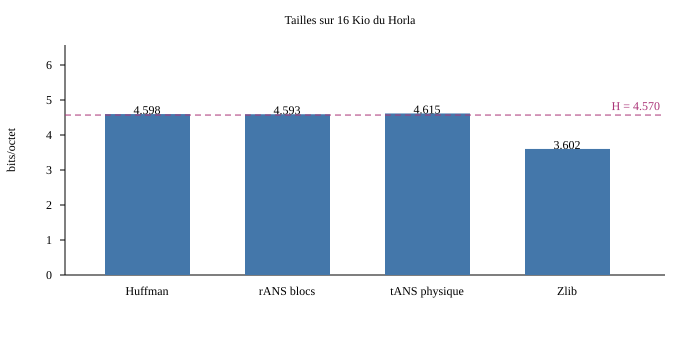

In [9]:
string E(string s)=>System.Security.SecurityElement.Escape(s);
var values=new[]{huff,8.0*rans.Length/n,8.0*physical/n,8.0*zipped.Length/n};var labels=new[]{"Huffman", "rANS blocs", "tANS physique", "Zlib"};
var svg=new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='700' height='340' viewBox='0 0 700 340'><rect width='700' height='340' fill='white'/><text x='350' y='24' text-anchor='middle'>Tailles sur 16 Kio du Horla</text><line x1='65' y1='275' x2='665' y2='275' stroke='black'/><line x1='65' y1='45' x2='65' y2='275' stroke='black'/><text x='15' y='150' transform='rotate(-90 15 150)' text-anchor='middle'>bits/octet</text>");
for(int tick=0;tick<=6;tick++){int y=275-tick*35;svg.Append($"<line x1='60' y1='{y}' x2='65' y2='{y}' stroke='black'/><text x='52' y='{y+4}' text-anchor='end'>{tick}</text>");}for(int i=0;i<values.Length;i++){double height=values[i]*35;string y=(275-height).ToString("F2",System.Globalization.CultureInfo.InvariantCulture),ht=height.ToString("F2",System.Globalization.CultureInfo.InvariantCulture);int px=105+i*140;svg.Append($"<rect x='{px}' y='{y}' width='85' height='{ht}' fill='#4477aa'/><text x='{px+42}' y='295' text-anchor='middle'>{E(labels[i])}</text><text x='{px+42}' y='{y}' text-anchor='middle'>{values[i].ToString("F3",System.Globalization.CultureInfo.InvariantCulture)}</text>");}string hy=(275-H*35).ToString("F2",System.Globalization.CultureInfo.InvariantCulture);
svg.Append($"<line x1='65' y1='{hy}' x2='665' y2='{hy}' stroke='#aa3377' stroke-dasharray='6 4'/><text x='660' y='{(275-H*35-5).ToString("F2",System.Globalization.CultureInfo.InvariantCulture)}' text-anchor='end' fill='#aa3377'>H = {H.ToString("F3",System.Globalization.CultureInfo.InvariantCulture)}</text>");svg.Append("</svg>");display(new Graphique(svg.ToString()));


### Temps de calcul

La construction des tables est mesurée séparément des encodages.


In [10]:
double Median(Action action){action();var times=new List<double>();for(int i=0;i<3;i++){var sw=Stopwatch.StartNew();action();sw.Stop();times.Add(sw.Elapsed.TotalMilliseconds);}times.Sort();return times[1];}
double MedianPrepare(Func<Action> prepare){prepare()();var times=new List<double>();for(int i=0;i<3;i++){var action=prepare();var sw=Stopwatch.StartNew();action();sw.Stop();times.Add(sw.Elapsed.TotalMilliseconds);}times.Sort();return times[1];}
var buildMs=Median(()=>{var t=new Tans(Tans.Scale(freq,12),12);});
var ransMs=Median(()=>{var b=Rans.BlocksEncode(tranche,freq,2048);});
var ransDecMs=Median(()=>{if(!Rans.BlocksDecode(rans,freq,2048,n).SequenceEqual(tranche))throw new Exception("rANS");});
var tansMs=Median(()=>{var b=table.Encode(tranche);});
var tansDecMs=MedianPrepare(()=>{var b=table.Encode(tranche);return ()=>{if(!table.Decode(b,n).SequenceEqual(tranche))throw new Exception("tANS");};});
var huffMs=Median(()=>{var result=new List<byte>();int count=0;foreach(int symbol in tranche){var c=codes[symbol];for(int j=c.bits-1;j>=0;j--){if(count%8==0)result.Add(0);if(((c.value>>j)&1)!=0)result[count/8]|=(byte)(1<<(7-count%8));count++;}}if(count!=used||!result.SequenceEqual(packed))throw new Exception("Huffman");});
var zlibMs=Median(()=>{using var ms=new MemoryStream();using(var zs=new ZLibStream(ms,CompressionLevel.SmallestSize,true))zs.Write(rawBytes);});
Console.WriteLine($"Médiane de 3 mesures après chauffe, ms : construction échelle/tables tANS {buildMs:F2} ; Huffman encodage {huffMs:F2} ; rANS encodage {ransMs:F2}, décodage {ransDecMs:F2} ; tANS encodage {tansMs:F2}, décodage {tansDecMs:F2} ; zlib compression {zlibMs:F2}.");
Console.WriteLine("Huffman utilise ses codes préconstruits ; tANS ses tables préconstruites ; rANS reconstruit le modèle à chaque appel. La comparaison des octets Huffman et les contrôles de retour sont inclus dans leurs mesures respectives. Le flot tANS frais est préparé hors chronomètre ; mesures locales.");


Médiane de 3 mesures après chauffe, ms : construction échelle/tables tANS 7.78 ; Huffman encodage 2.21 ; rANS encodage 85.44, décodage 90.10 ; tANS encodage 15.29, décodage 0.89 ; zlib compression 0.54.


Huffman utilise ses codes préconstruits ; tANS ses tables préconstruites ; rANS reconstruit le modèle à chaque appel. La comparaison des octets Huffman et les contrôles de retour sont inclus dans leurs mesures respectives. Le flot tANS frais est préparé hors chronomètre ; mesures locales.


Les médianes mesurent ces implémentations sur cette machine et ne sont pas des performances universelles des algorithmes.


Les résultats rapprochent les codeurs entropiques de l'entropie marginale ; tANS peut coûter davantage que Huffman sur ce corpus. Zlib exploite aussi l'ordre des octets. Les modèles non transmis empêchent de comparer ces nombres comme des tailles complètes de fichiers autonomes.

## À retenir

- rANS inverse chaque transition et retrouve l'état initial.
- tANS échange de la mémoire de table contre un état borné ; le flot est LIFO.
- Charge logique, état, bourrage, cadre et modèle sont des coûts distincts.

## Vérifiez votre compréhension

1. Pourquoi Huffman paie-t-il un bit au symbole dominant dans le cas binaire ?

<details><summary>Réponse</summary>Un code préfixe binaire non trivial doit distinguer les deux symboles par des mots non vides.</details>

2. La divisibilité suffit-elle pour une croissance rANS idéale ?

<details><summary>Réponse</summary>Non, le cumul intervient aussi dans la condition d'égalité.</details>

## Pour aller plus loin

Consultez le [carnet Python](Compression-04-ANS-Python.ipynb), puis [Duda, Asymmetric Numeral Systems](https://arxiv.org/abs/1311.2540) et le [code source de FSE](https://github.com/facebook/zstd/blob/dev/lib/common/fse.h).
